In [1]:
# conda env 'vis2'
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent.parent.parent

import sys
sys.path.append(str(PROJECT_ROOT))

from src.utils.util import load_sensor_dict, load_config, set_labels
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import glob
import at3d


In [2]:
savefigs = True

VERSION = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08'
DEFAULT = VERSION / 'default'
FIGURE_OUT = DEFAULT / 'figures'
FIGURE_OUT.mkdir(parents=True, exist_ok=True)

config = load_config(DEFAULT / 'config.yml')

In [3]:
data = {}
data['obs'] = {'files': [config['obs_file']]}
data['open'] = {'files': sorted((VERSION / 'default' / 'iterations').glob('iter*.nc'))}
data['periodic'] = {'files': sorted((VERSION / 'HBC' / 'periodic' / 'iterations').glob('iter*.nc'))}

In [4]:
for k in data:
    try:
        sensors, solvers, rte_grid = at3d.util.load_forward_model(data[k]['files'][-1])
        data[k]['sensors'] = sensors
        data[k]['solvers'] = solvers
        data[k]['rte_grid'] = rte_grid
        data[k]['cloud'] = solvers[0.67].medium['cloud']
        data[k]['sl'] = sensors['MISR']['sensor_list']
    except:
        sensors = load_sensor_dict(data[k]['files'][-1])
        solvers = None
        rte_grid = None
        data[k]['sensors'] = sensors
        data[k]['sl'] = sensors['MISR']['sensor_list']
    del sensors, solvers, rte_grid

cvm = xr.load_dataset(config['cloud_volume_mask_file'])

/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '71'. Max cell optical depth: '3.4591331481933594'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3

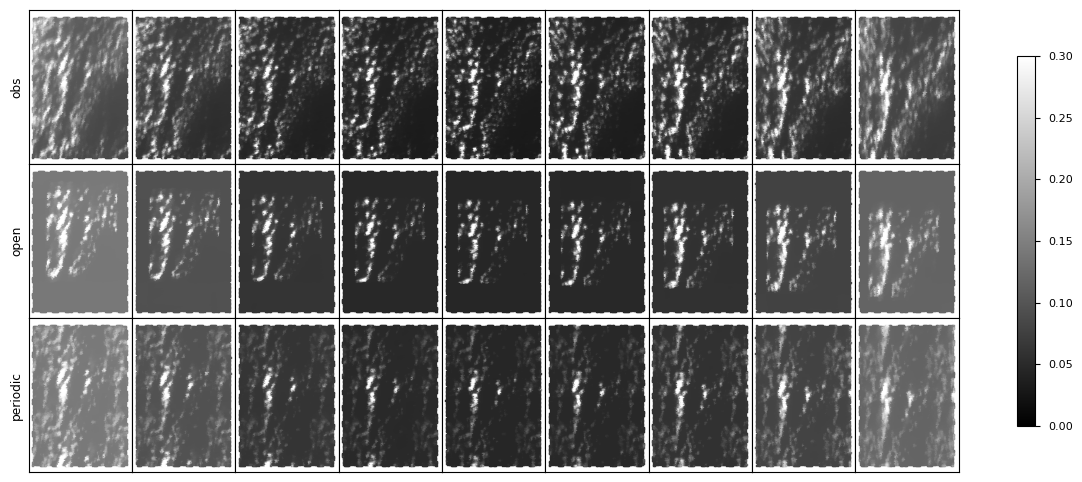

In [5]:
s = 2
vmin = 0
vmax = 0.3

plt.style.use('seaborn-v0_8-paper')
n = len(list(data.keys()))
f, ax = plt.subplots(n, 9, figsize=(15,2*n))
plt.subplots_adjust(wspace=0, hspace=0)
for i, k in enumerate(data):
    for j, cam in enumerate(data[k]['sl']):
        scat = ax[i, j].scatter(cam.ray_x.data, cam.ray_y.data, s=s, c=cam.I.data*np.pi/cam.mu0, marker='s', cmap='gray', vmin=vmin, vmax=vmax)
        ax[i, j].set_xlim([-4, 22])
        ax[i, j].set_ylim([-7, 25])
        ax[i, j].set_xticks([])
        ax[i, j].set_yticks([])
    ax[i, 0].set_ylabel(k)
plt.colorbar(scat, ax=ax[:], shrink=0.8)

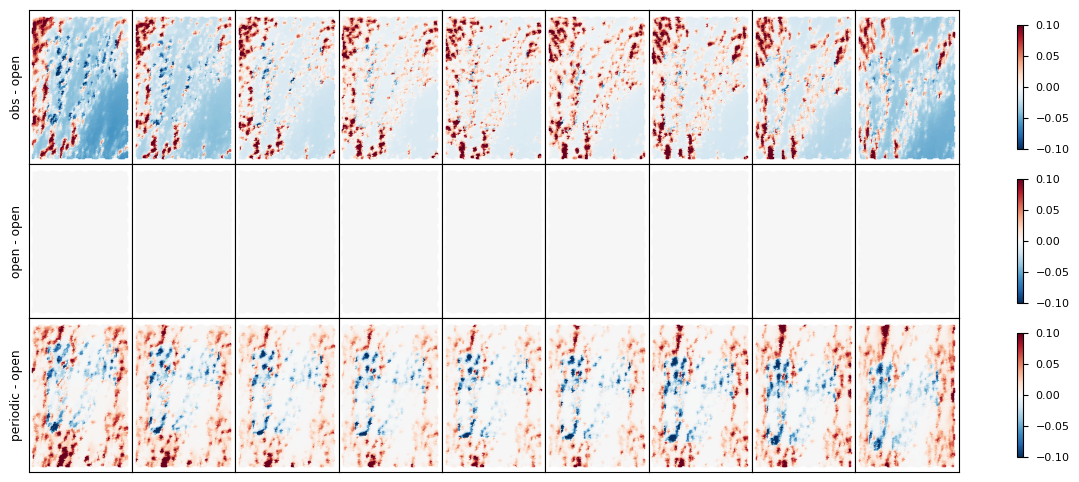

In [6]:
s = 2
vrange = [0.1, 0.1, 0.1]

plt.style.use('seaborn-v0_8-paper')
n = len(list(data.keys()))
f, ax = plt.subplots(n, 9, figsize=(15,2*n))
plt.subplots_adjust(wspace=0, hspace=0)
for i, k in enumerate(data):
    for j, (cam, defcam) in enumerate(zip(data[k]['sl'], data['open']['sl'])):
        I = (cam.I.data*np.pi/cam.mu0) - (defcam.I.data*np.pi/defcam.mu0)
        scat = ax[i, j].scatter(cam.ray_x.data, cam.ray_y.data, s=s, c=I, marker='s', cmap='RdBu_r', vmin=-vrange[i], vmax=vrange[i])
        ax[i, j].set_xlim([-4, 22])
        ax[i, j].set_ylim([-7, 25])
        ax[i, j].set_xticks([])
        ax[i, j].set_yticks([])
    ax[i, 0].set_ylabel('{} - open'.format(k))
    plt.colorbar(scat, ax=ax[i, :], shrink=0.8)

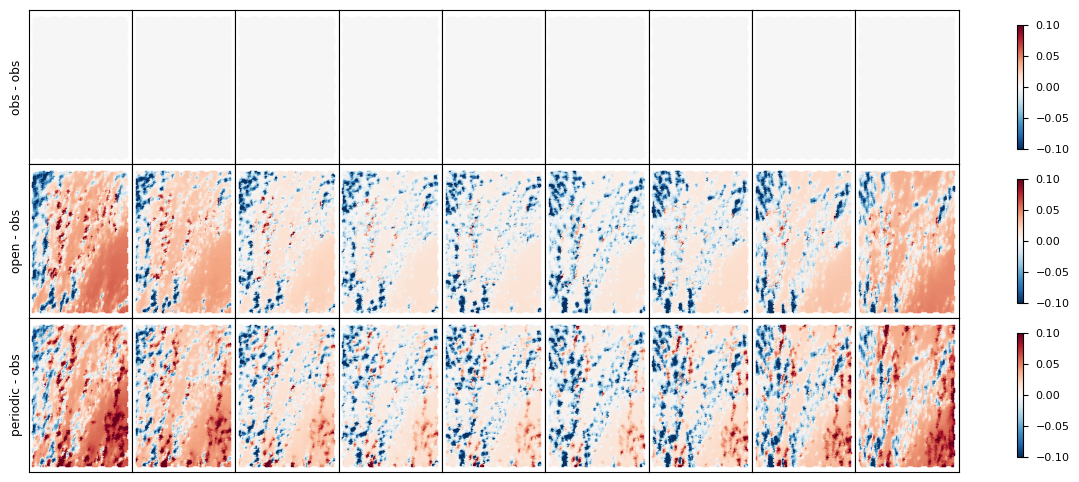

In [7]:
s = 2
vrange = [0.1, 0.1, 0.1]

plt.style.use('seaborn-v0_8-paper')
n = len(list(data.keys()))
f, ax = plt.subplots(n, 9, figsize=(15,2*n))
plt.subplots_adjust(wspace=0, hspace=0)
for i, k in enumerate(data):
    for j, (cam, defcam) in enumerate(zip(data[k]['sl'], data['obs']['sl'])):
        I = (cam.I.data*np.pi/cam.mu0) - (defcam.I.data*np.pi/defcam.mu0)
        scat = ax[i, j].scatter(cam.ray_x.data, cam.ray_y.data, s=s, c=I, marker='s', cmap='RdBu_r', vmin=-vrange[i], vmax=vrange[i])
        ax[i, j].set_xlim([-4, 22])
        ax[i, j].set_ylim([-7, 25])
        ax[i, j].set_xticks([])
        ax[i, j].set_yticks([])
    ax[i, 0].set_ylabel('{} - obs'.format(k))
    plt.colorbar(scat, ax=ax[i, :], shrink=0.8)

Text(0, 0.5, 'Periodic Extinction (1/km)')

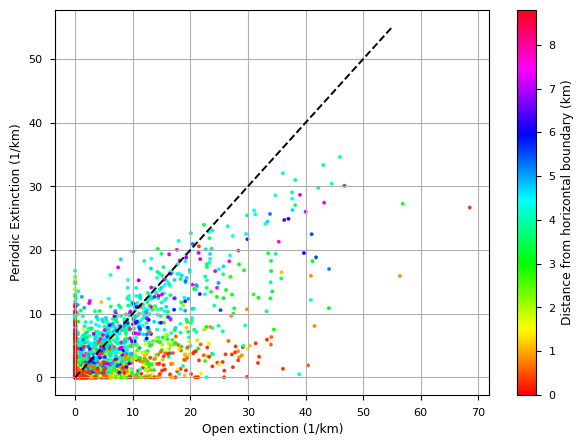

In [8]:
tmp = data['open']['cloud']
X, Y, Z = np.meshgrid(tmp.x.data, tmp.y.data, tmp.z.data, indexing='ij')
left_bottom = np.minimum(X, Y)
right_top = np.minimum(np.abs(17.6 - X), np.abs(17.6 - Y))
hdist = np.minimum(left_bottom, right_top)

f, ax = plt.subplots(1, 1, figsize=(7, 5))
scat = ax.scatter(np.ravel(data['open']['cloud'].extinction.data), np.ravel(data['periodic']['cloud'].extinction.data), s=6, c=np.ravel(hdist), cmap='hsv')
plt.colorbar(scat, ax=ax, label='Distance from horizontal boundary (km)')
ax.plot([0, 55], [0, 55], 'k--')
ax.grid()
ax.set_xlabel('Open extinction (1/km)')
ax.set_ylabel('Periodic Extinction (1/km)')

In [9]:
def rmse(x_r, x_t):
    return 100 * (np.sum((x_r - x_t)**2))**0.5 / (np.sum(x_t)**2)**0.5

def bias(x_r, x_t):
    return 100 * (np.sum(np.abs(x_r)) - np.sum(np.abs(x_t))) / (np.sum(np.abs(x_t)))

## Figure 16: AT3D MISR HBC

/tmp/ipykernel_3518523/1660792670.py:2: RuntimeWarning: divide by zero encountered in scalar divide
  return 100 * (np.sum((x_r - x_t)**2))**0.5 / (np.sum(x_t)**2)**0.5
/tmp/ipykernel_3518523/1660792670.py:5: RuntimeWarning: divide by zero encountered in scalar divide
  return 100 * (np.sum(np.abs(x_r)) - np.sum(np.abs(x_t))) / (np.sum(np.abs(x_t)))
/tmp/ipykernel_3518523/1660792670.py:2: RuntimeWarning: invalid value encountered in scalar divide
  return 100 * (np.sum((x_r - x_t)**2))**0.5 / (np.sum(x_t)**2)**0.5
/tmp/ipykernel_3518523/1660792670.py:5: RuntimeWarning: invalid value encountered in scalar divide
  return 100 * (np.sum(np.abs(x_r)) - np.sum(np.abs(x_t))) / (np.sum(np.abs(x_t)))


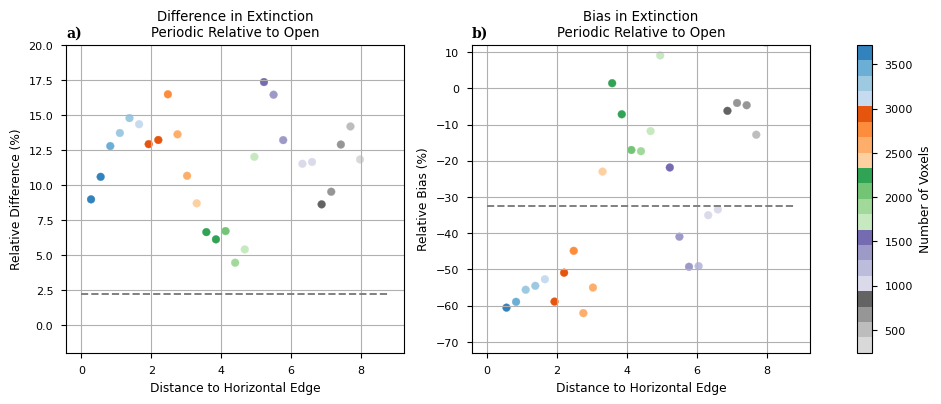

In [10]:
distances = np.arange(0, 9.1, 0.275) - 0.275/2
d = np.zeros(len(distances) - 1)
n = np.zeros(len(distances) - 1)
rel_diffs = np.zeros(len(distances) - 1)
rel_biases = np.zeros(len(distances) - 1)
for i in range(len(distances) - 1):
    d[i] = 0.5 * (distances[i] + distances[i+1])
    cond = (hdist > distances[i]) & (hdist < (distances[i+1]))
    n[i] = np.sum(cond)
    rel_diffs[i] = rmse(np.ravel(data['periodic']['cloud'].extinction.data[cond]), np.ravel(data['open']['cloud'].extinction.data[cond]))
    rel_biases[i] = bias(np.ravel(data['periodic']['cloud'].extinction.data[cond]), np.ravel(data['open']['cloud'].extinction.data[cond]))

overall_d = rmse(np.ravel(data['periodic']['cloud'].extinction.data), np.ravel(data['open']['cloud'].extinction.data))
overall_b = bias(np.ravel(data['periodic']['cloud'].extinction.data), np.ravel(data['open']['cloud'].extinction.data))

scat_cmap = 'tab20c_r'
f, ax = plt.subplots(1, 2, figsize=(12, 4), sharex=False)
ax[0].scatter(d, rel_diffs, c=n, cmap=scat_cmap)
ax[0].plot([0, 8.8], [overall_d, overall_d], '--', color='gray', label='Whole Domain')
scat = ax[1].scatter(d, rel_biases, c=n, cmap=scat_cmap)
plt.colorbar(scat, ax=ax[:], label='Number of Voxels')
ax[1].plot([0, 8.8], [overall_b, overall_b], '--', color='gray', label='Whole Domain')
ax[0].set_title('Difference in Extinction\nPeriodic Relative to Open')
ax[0].set_ylabel('Relative Difference (%)')
ax[1].set_title('Bias in Extinction\nPeriodic Relative to Open')
ax[1].set_ylabel('Relative Bias (%)')
ax[0].grid()
ax[1].grid()
ax[0].set_xlabel('Distance to Horizontal Edge')
ax[1].set_xlabel('Distance to Horizontal Edge')
ax[0].set_ylim([-2, 20])
ax[1].set_ylim([-73, 12])

set_labels(ax.flatten())

if(savefigs):
    plt.savefig(
        FIGURE_OUT / 'AT3D_MISR_HBC.png',
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )

In [39]:
pd_cloud = data['periodic']['cloud']
t = 17.6
pd_cloud.extinction.sel(x=slice(8.8-t/2,8.8+t/2), y=slice(8.8-t/2,8.8+t/2)).copy(deep=True)

<xarray.DataArray 'extinction' (x: 65, y: 65, z: 15)>
array([[[0., 0., ..., 0., 0.],
        [0., 0., ..., 0., 0.],
        ...,
        [0., 0., ..., 0., 0.],
        [0., 0., ..., 0., 0.]],

       [[0., 0., ..., 0., 0.],
        [0., 0., ..., 0., 0.],
        ...,
        [0., 0., ..., 0., 0.],
        [0., 0., ..., 0., 0.]],

       ...,

       [[0., 0., ..., 0., 0.],
        [0., 0., ..., 0., 0.],
        ...,
        [0., 0., ..., 0., 0.],
        [0., 0., ..., 0., 0.]],

       [[0., 0., ..., 0., 0.],
        [0., 0., ..., 0., 0.],
        ...,
        [0., 0., ..., 0., 0.],
        [0., 0., ..., 0., 0.]]])
Coordinates:
  * x        (x) float64 0.0 0.275 0.55 0.825 1.1 ... 16.78 17.05 17.33 17.6
  * y        (y) float64 0.0 0.275 0.55 0.825 1.1 ... 16.78 17.05 17.33 17.6
  * z        (z) float64 0.0 0.1 0.2 0.3 0.4 0.5 0.6 ... 0.9 1.0 1.1 1.2 1.3 1.4
    reff     (x, y, z) float64 ...
    veff     (x, y, z) float64 ...

In [40]:
T

array([ 2.2 ,  2.75,  3.3 ,  3.85,  4.4 ,  4.95,  5.5 ,  6.05,  6.6 ,
        7.15,  7.7 ,  8.25,  8.8 ,  9.35,  9.9 , 10.45, 11.  , 11.55,
       12.1 , 12.65, 13.2 , 13.75, 14.3 , 14.85, 15.4 , 15.95, 16.5 ,
       17.05, 17.6 ])

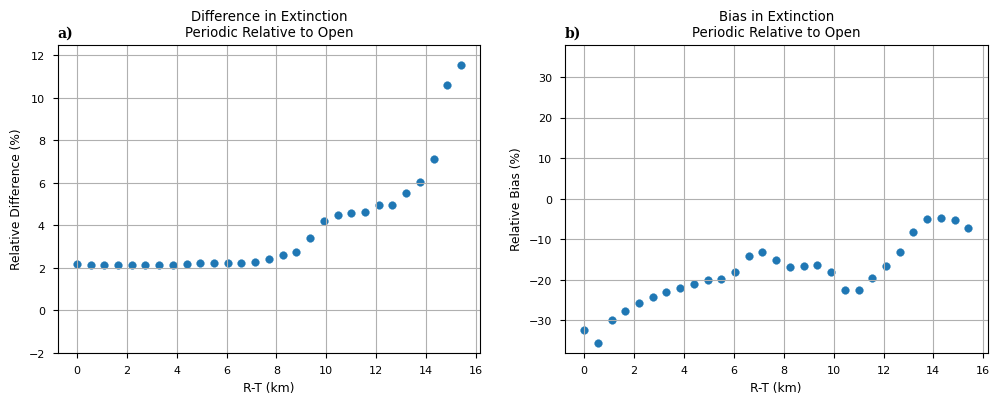

In [49]:
T = np.arange(2.2, 17.61, 2*0.275)
R = 17.6
rel_diffs = np.zeros(T.shape)
rel_biases = np.zeros(T.shape)
pd_cloud = data['periodic']['cloud']
op_cloud = data['open']['cloud']
eps = 0.01
for i, t in enumerate(T):
    pd_tmp = pd_cloud.extinction.sel(x=slice(8.8-t/2-eps,8.8+t/2+eps), y=slice(8.8-t/2-eps,8.8+t/2+eps)).copy(deep=True)
    op_tmp = op_cloud.extinction.sel(x=slice(8.8-t/2-eps,8.8+t/2+eps), y=slice(8.8-t/2-eps,8.8+t/2+eps)).copy(deep=True)
    t_tmp = np.max(pd_tmp.x.data) - np.min(pd_tmp.x.data)
    assert np.isclose(t, t_tmp), print('t = {}\nt_tmp = {}\n{}'.format(t, t_tmp, pd_tmp))
    rel_diffs[i] = rmse(np.ravel(pd_tmp.data), np.ravel(op_tmp.data))
    rel_biases[i] = bias(np.ravel(pd_tmp.data), np.ravel(op_tmp.data))

overall_d = rmse(np.ravel(data['periodic']['cloud'].extinction.data), np.ravel(data['open']['cloud'].extinction.data))
overall_b = bias(np.ravel(data['periodic']['cloud'].extinction.data), np.ravel(data['open']['cloud'].extinction.data))

scat_cmap = 'tab20c_r'
f, ax = plt.subplots(1, 2, figsize=(12, 4), sharex=False)
ax[0].scatter(R-T, rel_diffs)
ax[1].scatter(R-T, rel_biases)
# ax[0].plot(R-T, np.ones(T.shape)*overall_d, '--', color='gray', label='Whole Domain')
# ax[1].plot(R-T, np.ones(T.shape)*overall_b, '--', color='gray', label='Whole Domain')

ax[0].set_title('Difference in Extinction\nPeriodic Relative to Open')
ax[0].set_ylabel('Relative Difference (%)')
ax[1].set_title('Bias in Extinction\nPeriodic Relative to Open')
ax[1].set_ylabel('Relative Bias (%)')
ax[0].grid()
ax[1].grid()
ax[0].set_xlabel('R-T (km)')
ax[1].set_xlabel('R-T (km)')
ax[0].set_ylim([-2, 12.5])
ax[1].set_ylim([-38, 38])

set_labels(ax.flatten())

if(savefigs):
    plt.savefig(
        FIGURE_OUT / 'AT3D_MISR_HBC2.png',
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )

In [ ]:
import pandas as pd
import seaborn as sns

cond = cvm.cloud_volume_mask.data == 1

res = 1.1
distances = np.arange(0, 8.9+res, res) - res/2
d_strs = np.zeros(np.ravel(hdist[cond]).shape)
for i in range(len(distances) - 1):
    d_str = '{:.3f}'.format(0.5 * (distances[i] + distances[i+1]))
    cond_tmp = (hdist[cond] > distances[i]) & (hdist[cond] < (distances[i+1]))
    d_strs[cond_tmp] = d_str

df = pd.DataFrame(
    data=np.array([
        np.ravel(data['periodic']['cloud'].extinction.data[cond]),
        np.ravel(data['open']['cloud'].extinction.data[cond]),
        np.ravel(data['periodic']['cloud'].extinction.data[cond]) - np.ravel(data['open']['cloud'].extinction.data[cond]),
        (np.ravel(data['periodic']['cloud'].extinction.data[cond]) - np.ravel(data['open']['cloud'].extinction.data[cond])) / np.ravel(data['open']['cloud'].extinction.data[cond]),
        np.ravel(hdist[cond]),
        d_strs
    ]).T,
    columns=['periodic', 'open', 'difference', 'relative difference', 'horizontal distance float', 'horizontal distance']
)


In [ ]:
bins = np.arange(-20.5, 21.0, 1.0)
f, ax = plt.subplots(1, 2, figsize=(10,3))
sns.histplot(data=df, x='difference', ax=ax[0], bins=bins, hue='horizontal distance', multiple='stack')
sns.histplot(data=df, x='difference', ax=ax[1], bins=bins, hue='horizontal distance', multiple='fill', legend=None)


In [ ]:
ext_cmap = 'gist_heat_r'
x = np.arange(0, 17.7, 1.1)
vmax = 35
vrange = 20
plt.style.use('default')
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(len(x), 3, figsize=(14, 3*len(x)), sharey=True, sharex=True)
for i in range(len(x)):
    data['open']['cloud'].sel(x=x[i], method='nearest').extinction.plot(y='z', ax=ax[i, 0], vmin=0, vmax=vmax, cmap=ext_cmap)
    data['periodic']['cloud'].sel(x=x[i], method='nearest').extinction.plot(y='z', ax=ax[i, 1], vmin=0, vmax=vmax, cmap=ext_cmap)
    (data['periodic']['cloud'].extinction - data['open']['cloud'].extinction).sel(x=x[i], method='nearest').plot(y='z', ax=ax[i, 2], vmin=-vrange, vmax=vrange, cmap='RdBu_r')
    cvm.sel(x=x[i], method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[i, 0], colors='black', linewidths=0.5)
    cvm.sel(x=x[i], method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[i, 1], colors='black', linewidths=0.5)
    cvm.sel(x=x[i], method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[i, 2], colors='black', linewidths=0.5)
    ax[i, 0].set_title('x = {:.3f}\nOpen HBC'.format(x[i]))
    ax[i, 1].set_title('x = {:.3f}\nPeriodic HBC'.format(x[i]))
    ax[i, 2].set_title('x = {:.3f}\nPeriodic - Open HBC'.format(x[i]))

In [ ]:
tau_cmap = 'plasma'
vmin = 0
vmax = 11
vrange = 5.5

cloud_open = data['open']['cloud']
cloud_periodic = data['periodic']['cloud']
cloud_open['tau'] = cloud_open.extinction.integrate('z')
cloud_periodic['tau'] = cloud_periodic.extinction.integrate('z')

f, ax = plt.subplots(1, 3, figsize=(13, 3))
cloud_open.tau.plot(y='y', ax=ax[0], vmin=vmin, vmax=vmax, cmap=tau_cmap)
cloud_periodic.tau.plot(y='y', ax=ax[1], vmin=vmin, vmax=vmax, cmap=tau_cmap)
(cloud_periodic.tau - cloud_open.tau).plot(y='y', ax=ax[2], vmin=-vrange, vmax=vrange, cmap='RdBu_r')
ax[0].set_title('Open')
ax[1].set_title('Periodic')
ax[2].set_title('Periodic - Open')